In [9]:
%pip install numpy pandas matplotlib scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.exceptions import UndefinedMetricWarning

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
df = pd.read_csv("Chess_Data_ Cleaned_Openings_Grouped.csv")

df.head()

,id,Duplicate Ids,rated,created_at,last_move_at,Time Check,turns,Turn Categorised,victory_status,winner,...,Turns,Average Rating,Rating Difference,Outcome,moves,opening_eco,opening_name,opening_ply,Openings - Textsplit,Grouped Openings
0,W4vsJvbx,0,True,1.450000e+12,1.450000e+12,1,182,181 - 190,resign,black,...,182,1500.0,0,!,e3 e6 f3 Qf6 g3 Qxf3 Nxf3 Bb4 Qe2 Bxd2+ Kxd2 d...,A00,Van't Kruijs Opening,1,Van't,Van't Kruijs Opening
1,gK3xiIiz,0,False,1.502040e+12,1.502040e+12,0,171,171 - 180,outoftime,white,...,171,1500.0,0,!,e4 e5 Qh5 Nc6 Bc4 g6 Qf3 Nf6 d3 Nd4 Qd1 d5 Bb5...,C20,King's Pawn Game: Wayward Queen Attack,3,King's,King's Gambit
2,83ZP2v8Y,0,True,1.493550e+12,1.493550e+12,0,169,161 - 170,mate,white,...,169,1868.0,0,!,e4 d6 Nf3 Nd7 d4 e5 d5 Ngf6 Nc3 b6 Bg5 Be7 Nh4...,C41,Philidor Defense: Hanham Variation,6,Philidor,Philidor Defense
3,NcYIjf5n,0,False,1.450000e+12,1.450000e+12,1,149,141 - 150,draw,draw,...,149,1500.0,0,draw,e4 d6 f4 c5 b3 b6 Qg4 f6 Qh5+ Kd7 Qf5+ Kc7 Qd7...,B07,Rat Defense: Harmonist,3,Rat,Rat Defense: Antal Defense
4,Ejr8Xy15,0,True,1.500000e+12,1.500000e+12,1,148,141 - 150,mate,black,...,148,1693.0,0,!,e4 c5 Nf3 Nc6 Nc3 e6 Bb5 a6 Bxc6 bxc6 d4 cxd4 ...,B30,Sicilian Defense: Old Sicilian,4,Sicilian,Sicilian Defense


<Axes: xlabel='opening_name', ylabel='white_wins'>

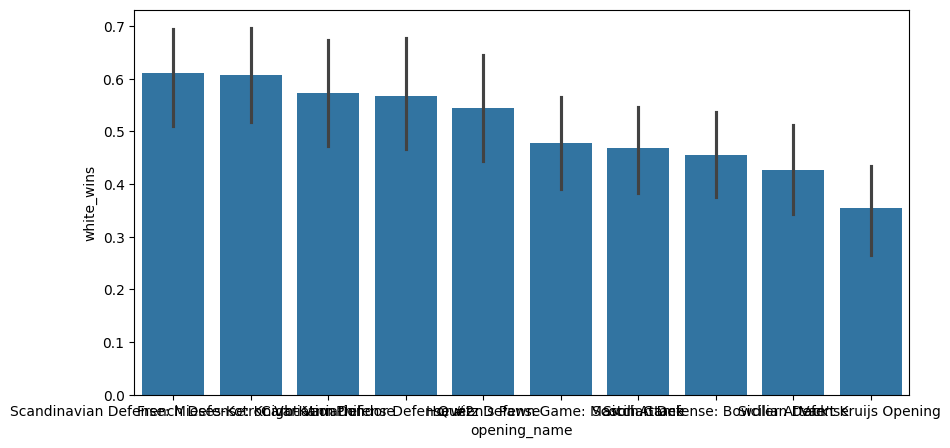

In [4]:
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]   # drop the empty trailing columns
df = df[df["winner"].isin(["white", "black"])].copy()
df["white_wins"] = (df["winner"] == "white").astype(int)

top10 = df["opening_name"].value_counts().head(10).index
plot_df = df[df["opening_name"].isin(top10)]
order = (plot_df.groupby("opening_name")["white_wins"]
                .mean().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_df, x="opening_name", y="white_wins", order=order, ax=ax)

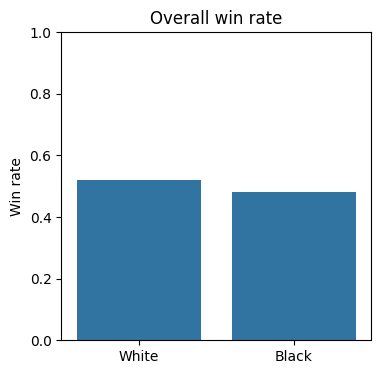

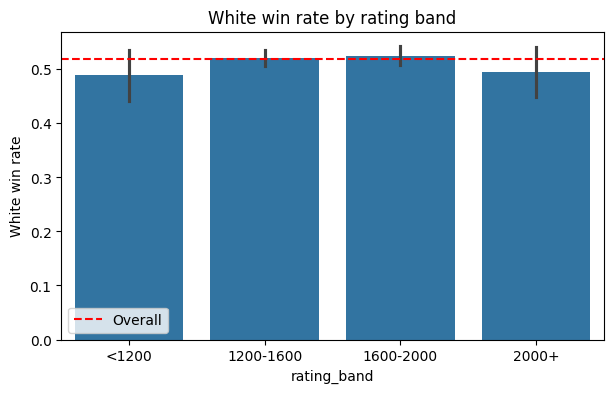

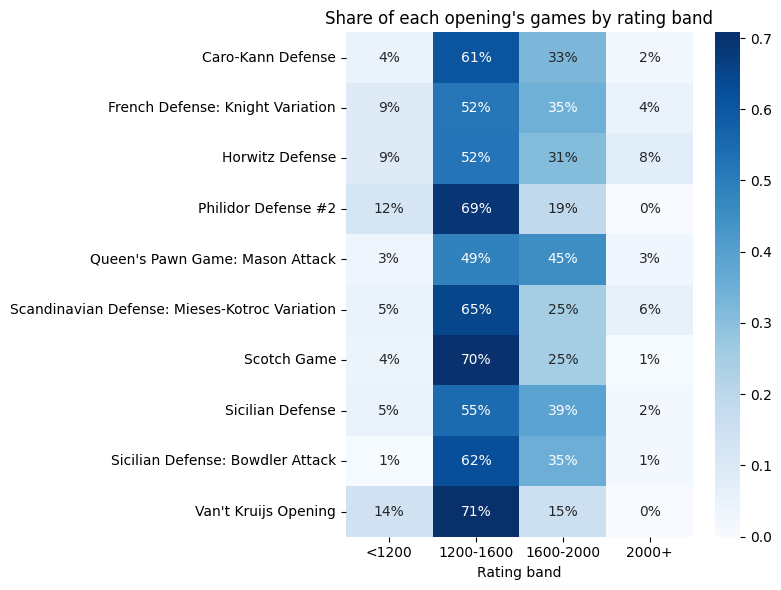

opening_name
Sicilian Defense: Bowdler Attack                 136
Sicilian Defense                                 131
Scotch Game                                      128
Queen's Pawn Game: Mason Attack                  115
Van't Kruijs Opening                             113
French Defense: Knight Variation                 112
Scandinavian Defense: Mieses-Kotroc Variation    108
Horwitz Defense                                   90
Philidor Defense #2                               90
Caro-Kann Defense                                 89
Name: count, dtype: int64
                                               games  white_win_rate
opening_name                                                        
Sicilian Defense: Bowdler Attack                 136        0.455882
Sicilian Defense                                 131        0.427481
Scotch Game                                      128        0.468750
Queen's Pawn Game: Mason Attack                  115        0.478261
Van't Kruijs Open

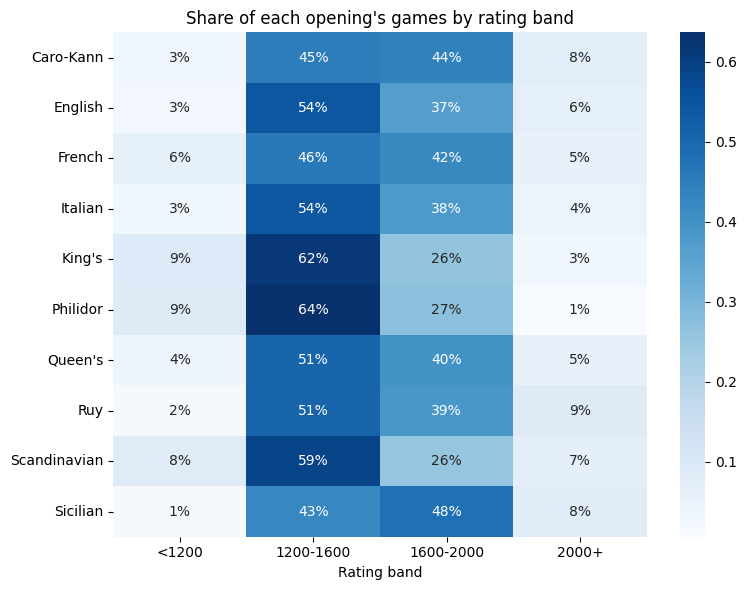

In [5]:
df["rating_band"] = pd.cut(df["Average Rating"],
                           bins=[0, 1200, 1600, 2000, 4000],
                           labels=["<1200", "1200-1600", "1600-2000", "2000+"])
overall = df["white_wins"].mean()

# 1. Overall: White vs Black win share (draws excluded)
fig, ax = plt.subplots(figsize=(4, 4))
sns.barplot(x=["White", "Black"],
            y=[overall, 1 - overall], ax=ax)
ax.set_ylabel("Win rate")
ax.set_title("Overall win rate")
ax.set_ylim(0, 1)

# 2. By opening: the chart from before
# (sns.barplot with y="opening_name" and x="white_wins")

# 3. By rating band
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=df, x="rating_band", y="white_wins", ax=ax)
ax.axhline(overall, color="red", linestyle="--", label="Overall")
ax.set_title("White win rate by rating band")
ax.set_ylabel("White win rate")
ax.legend()

# 4. Confounder check: share of each opening's games in each rating band
top10 = df["opening_name"].value_counts().head(10).index
plot_df = df[df["opening_name"].isin(top10)]
share = pd.crosstab(plot_df["opening_name"], plot_df["rating_band"],
                    normalize="index")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(share, annot=True, fmt=".0%", cmap="Blues", ax=ax)
ax.set_title("Share of each opening's games by rating band")
ax.set_xlabel("Rating band")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

top10_counts = df["opening_name"].value_counts().head(10)
print(top10_counts)
summary = (df[df["opening_name"].isin(top10_counts.index)]
             .groupby("opening_name")["white_wins"]
             .agg(games="count", white_win_rate="mean")
             .sort_values("games", ascending=False))
print(summary)

top10 = df["Openings - Textsplit"].value_counts().head(10).index
plot_df = df[df["Openings - Textsplit"].isin(top10)]
share = pd.crosstab(plot_df["Openings - Textsplit"], plot_df["rating_band"],
                    normalize="index")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(share, annot=True, fmt=".0%", cmap="Blues", ax=ax)
ax.set_title("Share of each opening's games by rating band")
ax.set_xlabel("Rating band")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


102 openings in total


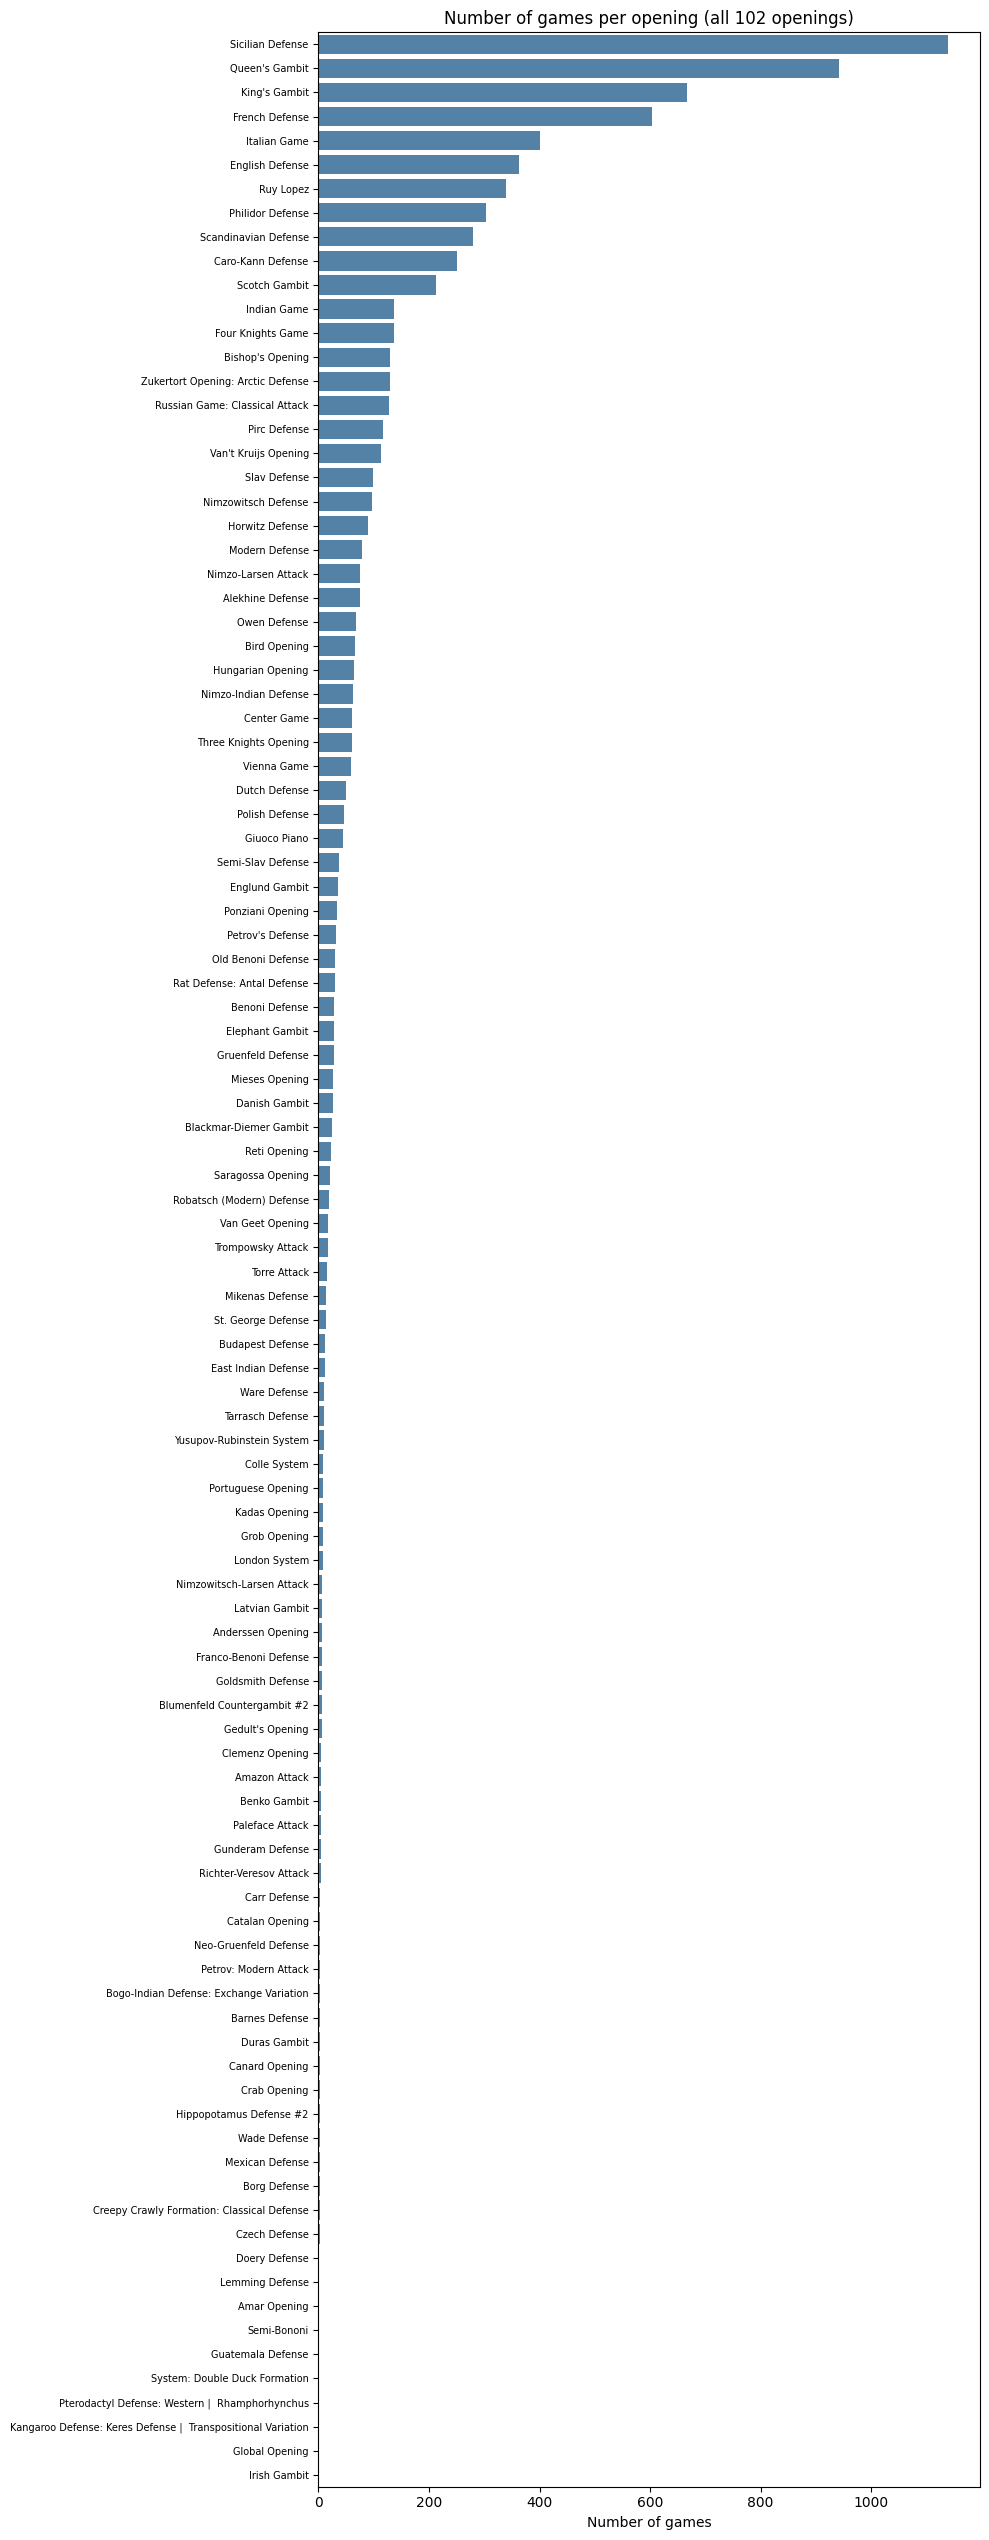

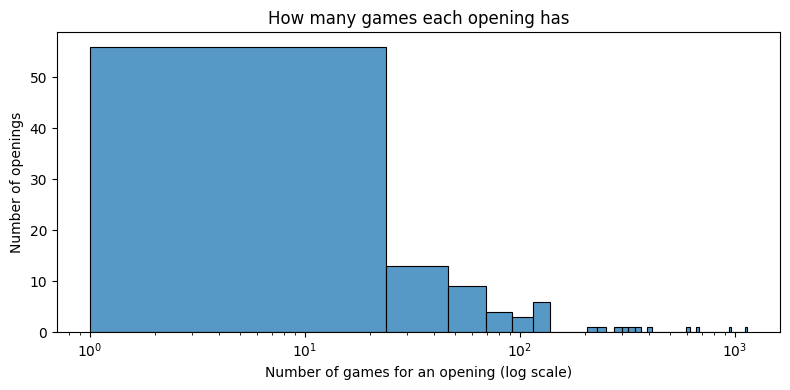

In [6]:
counts = df["Grouped Openings"].value_counts()
print(f"{len(counts)} openings in total")

# Scale the height to the number of openings so every label fits
fig, ax = plt.subplots(figsize=(10, max(5, len(counts) * 0.25)))
sns.barplot(x=counts.values, y=counts.index, color="steelblue", ax=ax)
ax.set_title(f"Number of games per opening (all {len(counts)} openings)")
ax.set_xlabel("Number of games")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(counts.values, bins=50, ax=ax)
ax.set_xscale("log")   # game counts are very skewed, so a log scale helps
ax.set_xlabel("Number of games for an opening (log scale)")
ax.set_ylabel("Number of openings")
ax.set_title("How many games each opening has")
plt.tight_layout()
plt.show()

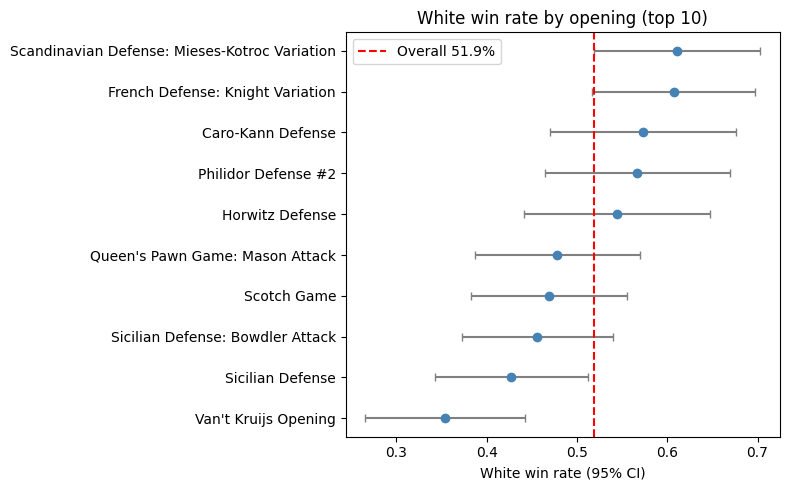

In [7]:
top10 = df["opening_name"].value_counts().head(10).index
g = df[df["opening_name"].isin(top10)].groupby("opening_name")["white_wins"]

stats = pd.DataFrame({"rate": g.mean(), "n": g.count()})
stats["se"] = np.sqrt(stats["rate"] * (1 - stats["rate"]) / stats["n"])
stats["lo"] = stats["rate"] - 1.96 * stats["se"]
stats["hi"] = stats["rate"] + 1.96 * stats["se"]
stats = stats.sort_values("rate")

overall = df["white_wins"].mean()
y = np.arange(len(stats))

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(stats["rate"], y,
            xerr=[stats["rate"] - stats["lo"], stats["hi"] - stats["rate"]],
            fmt="o", color="steelblue", ecolor="gray", capsize=3)
ax.axvline(overall, color="red", linestyle="--", label=f"Overall {overall:.1%}")
ax.set_yticks(y)
ax.set_yticklabels(stats.index)
ax.set_xlabel("White win rate (95% CI)")
ax.set_title("White win rate by opening (top 10)")
ax.legend()
plt.tight_layout()
plt.show()

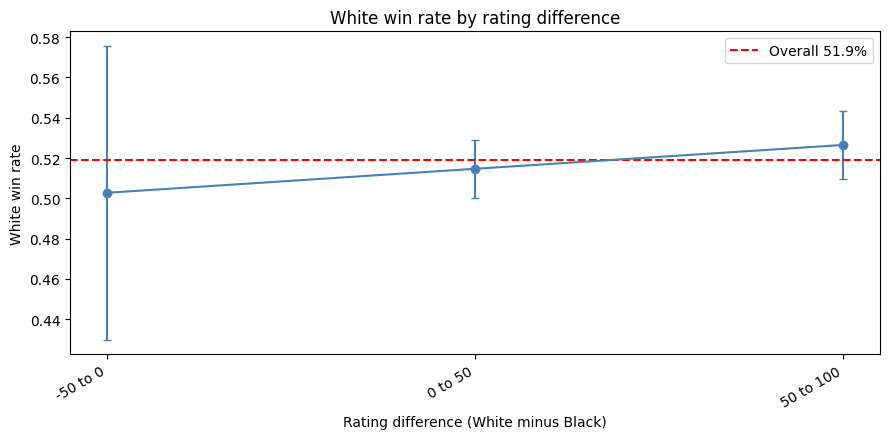

In [8]:
bins = [-1000, -200, -100, -50, 0, 50, 100, 200, 1000]
df["diff_band"] = pd.cut(df["Rating Difference"], bins=bins)

res = df.groupby("diff_band", observed=True)["white_wins"].agg(["mean", "count"])
se = np.sqrt(res["mean"] * (1 - res["mean"]) / res["count"])
x = np.arange(len(res))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(x, res["mean"], yerr=1.96 * se, fmt="-o", capsize=3, color="steelblue")
ax.axhline(overall, color="red", linestyle="--", label=f"Overall {overall:.1%}")
ax.set_xticks(x)
ax.set_xticklabels([f"{iv.left:.0f} to {iv.right:.0f}" for iv in res.index],
                   rotation=30, ha="right")
ax.set_xlabel("Rating difference (White minus Black)")
ax.set_ylabel("White win rate")
ax.set_title("White win rate by rating difference")
ax.legend()
plt.tight_layout()
plt.show()

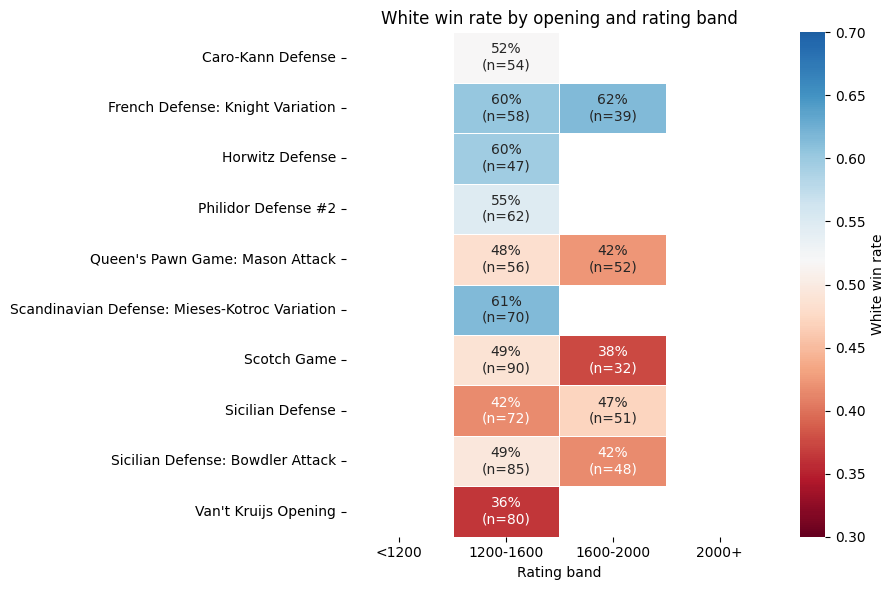

In [9]:
top10 = df["opening_name"].value_counts().head(10).index
plot_df = df[df["opening_name"].isin(top10)]

rate = plot_df.pivot_table(index="opening_name", columns="rating_band",
                           values="white_wins", aggfunc="mean", observed=False)
counts = plot_df.pivot_table(index="opening_name", columns="rating_band",
                             values="white_wins", aggfunc="count", observed=False)
rate = rate.where(counts >= 30)

labels = pd.DataFrame("", index=rate.index, columns=rate.columns)
for r in rate.index:
    for c in rate.columns:
        v, n = rate.loc[r, c], counts.loc[r, c]
        labels.loc[r, c] = "n<30" if pd.isna(v) else f"{v:.0%}\n(n={int(n)})"

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(rate, annot=labels, fmt="", cmap="RdBu", center=overall,
            vmin=0.3, vmax=0.7, linewidths=0.5, ax=ax,
            cbar_kws={"label": "White win rate"})
ax.set_title("White win rate by opening and rating band")
ax.set_xlabel("Rating band")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
#SLIDE 3 FEATURES; WHAT GOES INTO MODEL AND WHAT STAYS OUT

# Rating features (from White's point of view: positive = White is stronger)
df["rating_diff"] = df["white_rating"] - df["black_rating"]
df["avg_rating"] = (df["white_rating"] + df["black_rating"]) / 2

# Rating bands, used later to compare skill levels
df["rating_band"] = pd.cut(df["avg_rating"], bins=[0, 1400, 1800, 4000],
                           labels=["Under 1400", "1400-1800", "Over 1800"])

# About 100 openings: keep the 15 most common, group the rest as "Other"
top_openings = df["Grouped Openings"].value_counts().head(15).index
df["opening_group"] = df["Grouped Openings"].where(df["Grouped Openings"].isin(top_openings), "Other")

df["rated"] = df["rated"].astype(str)

numeric_features = ["rating_diff", "avg_rating", "opening_ply"]
categorical_features = ["opening_group", "Game Classification", "rated"]
features = numeric_features + categorical_features

df = df.dropna(subset=features + ["winner"])
X = df[features]
y = df["winner"]          # 'white', 'black' or 'draw'

df["opening_group"].value_counts()

opening_group
Other                                2296
Sicilian Defense                     1207
Queen's Gambit                        990
King's Gambit                         703
French Defense                        633
Italian Game                          427
English Defense                       375
Ruy Lopez                             364
Philidor Defense                      317
Scandinavian Defense                  295
Caro-Kann Defense                     268
Scotch Gambit                         221
Indian Game                           150
Bishop's Opening                      140
Four Knights Game                     140
Zukertort Opening: Arctic Defense     136
Name: count, dtype: int64

In [10]:
#SLIDE 4: MODELING APPROACH. 1. ## Slide 4: Models and modelling approach
#1. 80/20 train/test split, **stratified** (draws are rare, so every split needs some). The test set is used once at the end.
#2. A `Pipeline` scales the numeric columns and one-hot encodes the categories.
#3. Four models are compared with 5-fold stratified cross-validation:
   #- baseline (always predicts the most common result)
   #- logistic regression (week 6)
   #- decision tree (week 7)
   #- random forest (week 8)
#4. `class_weight="balanced"` makes the models pay attention to draws, which are rare.
#5. Main metric: **macro F1**, because accuracy is misleading with imbalanced classes (week 8).

RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows (kept aside):", len(X_test))

def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

preprocess = make_preprocess(numeric_features, categorical_features)

models = {
    "Baseline (most common)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree (depth 5)": DecisionTreeClassifier(max_depth=5, class_weight="balanced",
                                                      random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "f1_macro"]

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"model": name, **{m: scores[f"test_{m}"].mean() for m in scoring}})

cv_results = pd.DataFrame(rows).set_index("model").round(3)
cv_results

Training rows: 6929 | Test rows (kept aside): 1733


,accuracy,f1_macro
model,,
Baseline (most common),0.492,0.220
Logistic Regression,0.362,0.317
Decision Tree (depth 5),0.395,0.306
Random Forest,0.461,0.354


In [11]:
## Slide 5: Can openings predict who wins? (the research question)
#Use the same model with two feature sets: **ratings and game type only** vs **ratings, game type and opening**.
#If openings help predict the winner, the second should score higher. Then repeat this inside each rating band and each time control.
base_num, base_cat = ["rating_diff", "avg_rating"], ["Game Classification", "rated"]
open_num, open_cat = ["rating_diff", "avg_rating", "opening_ply"], ["opening_group", "Game Classification", "rated"]

def cv_macro_f1(data, num_cols, cat_cols, folds=5):
    pipe = Pipeline([("prep", make_preprocess(num_cols, cat_cols)),
                     ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
    cv_k = StratifiedKFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE)
    return cross_validate(pipe, data[num_cols + cat_cols], data["winner"],
                          cv=cv_k, scoring="f1_macro")["test_score"].mean()

train_df = df.loc[X_train.index]

without_opening = cv_macro_f1(train_df, base_num, base_cat)
with_opening = cv_macro_f1(train_df, open_num, open_cat)
print(f"Without opening: {without_opening:.3f}")
print(f"With opening:    {with_opening:.3f}")
print(f"Gain:            {with_opening - without_opening:+.3f}")

Without opening: 0.326
With opening:    0.317
Gain:            -0.010


/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointwise.T @ X + l2_reg_strength * weights
/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn

In [12]:
# Same comparison inside each rating band, time control and rated/casual group
rows = []
for group_col in ["rating_band", "Game Classification", "rated"]:
    for level, sub in train_df.groupby(group_col, observed=True):
        if len(sub) < 100 or sub["winner"].value_counts().min() < 5:
            continue   # too few games (or too few draws) for 5-fold CV
        a = cv_macro_f1(sub, base_num, [c for c in base_cat if c != group_col])
        b = cv_macro_f1(sub, open_num, [c for c in open_cat if c != group_col])
        rows.append({"compared by": group_col, "group": level, "games": len(sub),
                     "without opening": a, "with opening": b, "gain": b - a})

subgroup_results = pd.DataFrame(rows).round(3)
subgroup_results

/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointwise.T @ X + l2_reg_strength * weights
/Users/oisinfeeney/Library/Python/3.9/lib/python/site-packages/sklearn

,compared by,group,games,without opening,with opening,gain
0,rating_band,Under 1400,1498,0.307,0.306,-0.001
1,rating_band,1400-1800,3954,0.297,0.297,-0.000
2,rating_band,Over 1800,1477,0.374,0.342,-0.031
3,Game Classification,Blitz,618,0.316,0.320,0.003
4,Game Classification,Classic,348,0.353,0.358,0.005
5,Game Classification,Rapid,5963,0.321,0.310,-0.010
6,rated,False,893,0.351,0.330,-0.021
7,rated,True,6036,0.321,0.308,-0.013


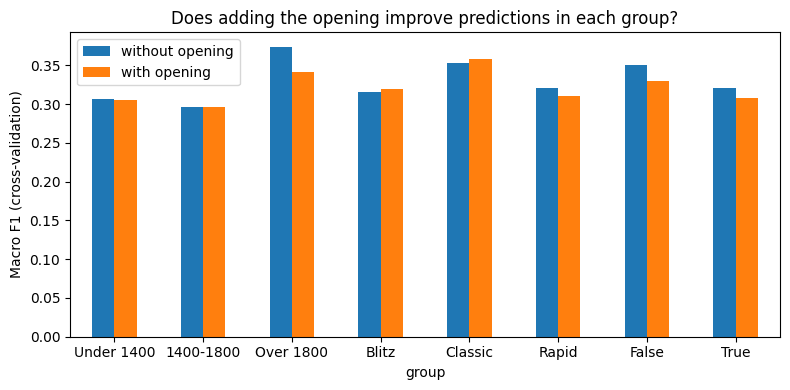

In [13]:
plot_df = subgroup_results.set_index("group")[["without opening", "with opening"]]
plot_df.plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Macro F1 (cross-validation)")
plt.title("Does adding the opening improve predictions in each group?")
plt.tight_layout()
plt.show()

Best model by CV macro F1: Random Forest
              precision    recall  f1-score   support

       black       0.49      0.49      0.49       789
        draw       0.08      0.09      0.08        92
       white       0.52      0.52      0.52       852

    accuracy                           0.48      1733
   macro avg       0.36      0.36      0.36      1733
weighted avg       0.48      0.48      0.48      1733



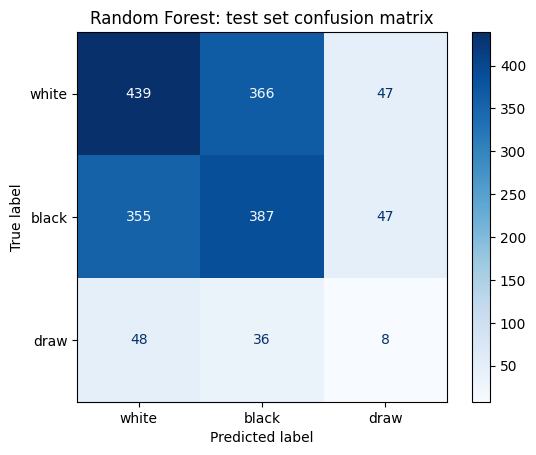

In [14]:
## Slide 6: Predictions and evaluation on the test set
#Retrain the best model (by CV macro F1) on all training data, then predict the test set **once**.
best_name = cv_results.drop("Baseline (most common)")["f1_macro"].idxmax()
print("Best model by CV macro F1:", best_name)

final_model = Pipeline([("prep", preprocess), ("model", models[best_name])])
final_model.fit(X_train, y_train)
test_pred = final_model.predict(X_test)

print(classification_report(y_test, test_pred))

labels = ["white", "black", "draw"]
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=labels, cmap="Blues")
plt.title(f"{best_name}: test set confusion matrix")
plt.show()

In [15]:
# Example predictions for the slide: predicted probabilities for 5 test games
probs = pd.DataFrame(final_model.predict_proba(X_test.head(5)),
                     columns=final_model.classes_, index=X_test.head(5).index).round(2)
examples = X_test.head(5)[["opening_group", "rating_diff", "Game Classification"]].join(probs)
examples["predicted"] = test_pred[:5]
examples["actual"] = y_test.head(5).values
examples

,opening_group,rating_diff,Game Classification,black,draw,white,predicted,actual
8341,Other,-95,Rapid,0.49,0.23,0.28,black,black
6739,Other,71,Blitz,0.43,0.14,0.43,white,white
7104,French Defense,-76,Rapid,0.38,0.25,0.37,black,white
7892,Philidor Defense,87,Rapid,0.26,0.19,0.55,white,white
3107,Other,27,Rapid,0.39,0.25,0.35,black,white


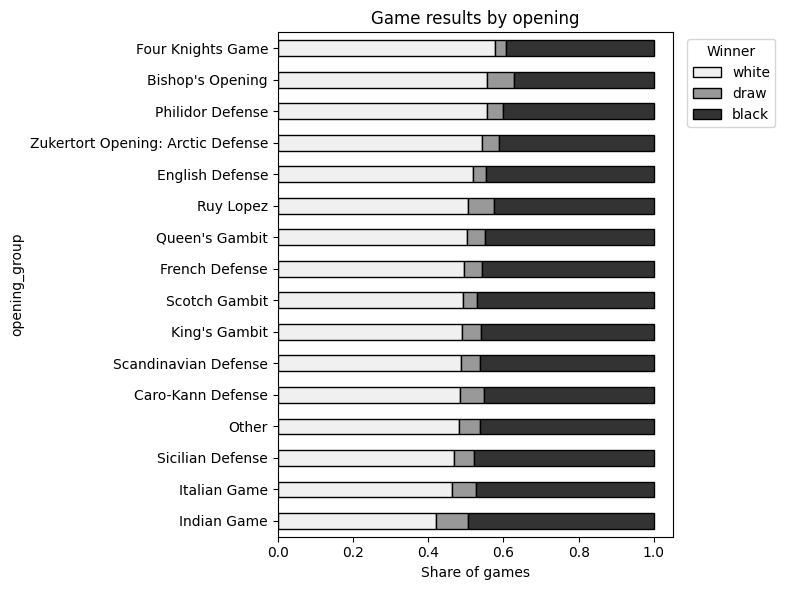

In [17]:
## Slide 7: Interpretation
#1. Observed results by opening: which openings are linked to more White wins, Black wins or draws.
#2. Random forest feature importances: what the model relies on most.

#These are **associations, not causes**. Players choose their openings, so stronger or more aggressive players may favour certain lines.

results_by_opening = (pd.crosstab(df["opening_group"], df["winner"], normalize="index")
                      [["white", "draw", "black"]].sort_values("white"))
results_by_opening.plot.barh(stacked=True, figsize=(8, 6),
                             color=["#f0f0f0", "#999999", "#333333"], edgecolor="black")
plt.xlabel("Share of games")
plt.title("Game results by opening")
plt.legend(title="Winner", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

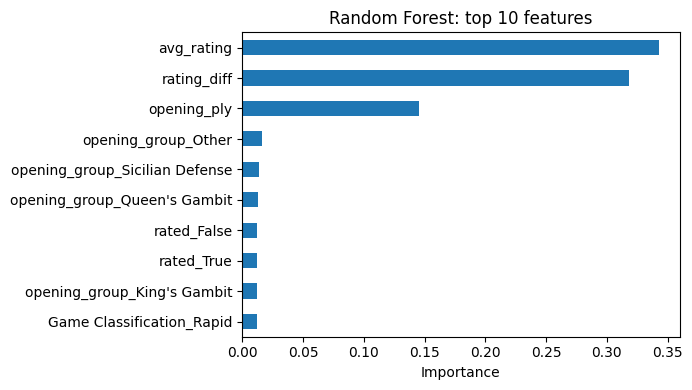

In [18]:
rf = Pipeline([("prep", preprocess), ("model", models["Random Forest"])])
rf.fit(X_train, y_train)

importances = pd.Series(
    rf.named_steps["model"].feature_importances_,
    index=rf.named_steps["prep"].get_feature_names_out(),
).sort_values(ascending=False).head(10)
importances.index = importances.index.str.replace("num__", "").str.replace("cat__", "")

importances.sort_values().plot.barh(figsize=(7, 4))
plt.xlabel("Importance")
plt.title("Random Forest: top 10 features")
plt.tight_layout()
plt.show()